In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
df = pd.read_csv(r"E:\BE\Practical\ML_Practical\Practical_2\emails.csv")

In [3]:
df.head()

,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [4]:
df.isnull().sum()

Email No.     0
the           0
to            0
ect           0
and           0
             ..
military      0
allowing      0
ff            0
dry           0
Prediction    0
Length: 3002, dtype: int64

In [5]:
df.isnull().sum().sum()

np.int64(0)

In [6]:
df.dropna(inplace=True)
df.drop_duplicates(inplace=True)

In [7]:
# Remove email ID column
df.drop(columns=["Email No."], errors="ignore", inplace=True)

In [8]:
X = df.drop("Prediction", axis=1)
y = df["Prediction"]

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [10]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [11]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
pred1 = knn.predict(X_test)

In [12]:
svm = SVC(kernel="linear")
svm.fit(X_train, y_train)
pred2 = svm.predict(X_test)


In [13]:
print("KNN Accuracy:", accuracy_score(y_test, pred1))
print("KNN Confusion Matrix:\n", confusion_matrix(y_test, pred1))
print("KNN Classification Report:\n", classification_report(y_test, pred1))

KNN Accuracy: 0.8338164251207729
KNN Confusion Matrix:
 [[576 159]
 [ 13 287]]
KNN Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.78      0.87       735
           1       0.64      0.96      0.77       300

    accuracy                           0.83      1035
   macro avg       0.81      0.87      0.82      1035
weighted avg       0.88      0.83      0.84      1035



In [14]:
print("SVM Accuracy:", accuracy_score(y_test, pred2))
print("SVM Confusion Matrix:\n", confusion_matrix(y_test, pred2))
print("SVM Classification Report:\n", classification_report(y_test, pred2))

SVM Accuracy: 0.9507246376811594
SVM Confusion Matrix:
 [[709  26]
 [ 25 275]]
SVM Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.96      0.97       735
           1       0.91      0.92      0.92       300

    accuracy                           0.95      1035
   macro avg       0.94      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035



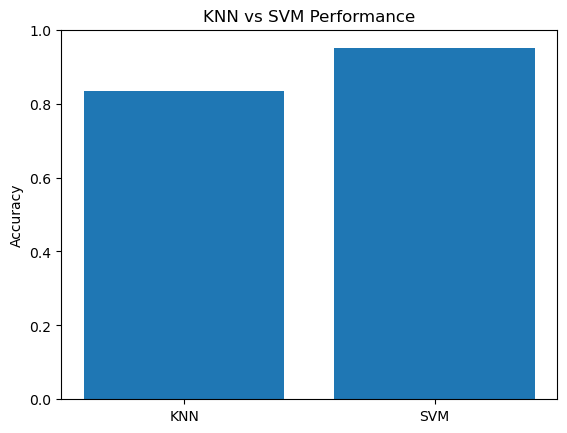

In [15]:
accuracy = [
    accuracy_score(y_test, pred1),
    accuracy_score(y_test, pred2)
]

plt.bar(["KNN", "SVM"], accuracy)
plt.ylabel("Accuracy")
plt.title("KNN vs SVM Performance")
plt.ylim(0, 1)
plt.show()